In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import seaborn as sns


# 1. Generating Synthetic Data


In [47]:
#For reproducibility
np.random.seed(42)

# # Normally distributed feature
feat_1 = np.random.normal(loc=60, scale=6, size=200)

# Skewed feature (exponential distribution)
feat_2 = np.random.exponential(scale = 60, size = 200)

# Feature with extreme outliers 
f = np.random.normal(loc = 15, scale = 3, size = 195)
feat_3 = np.append(f, [f.max() + 50, f.max() + 100, f.max() + 150, f.max() + 200, f.max() + 250])
df = pd.DataFrame({"Normal" : feat_1, "Skewed" : feat_2, "With_outlier" : feat_3})
df.head()

,Normal,Skewed,With_outlier
0,62.980285,125.916518,14.673720
1,59.170414,81.002055,16.205135
2,63.886131,71.644466,17.070432
3,69.138179,72.737253,13.796339
4,58.595080,26.729541,15.672277


# 2. Visualizing Original Distributions using Boxplots and KDE plots


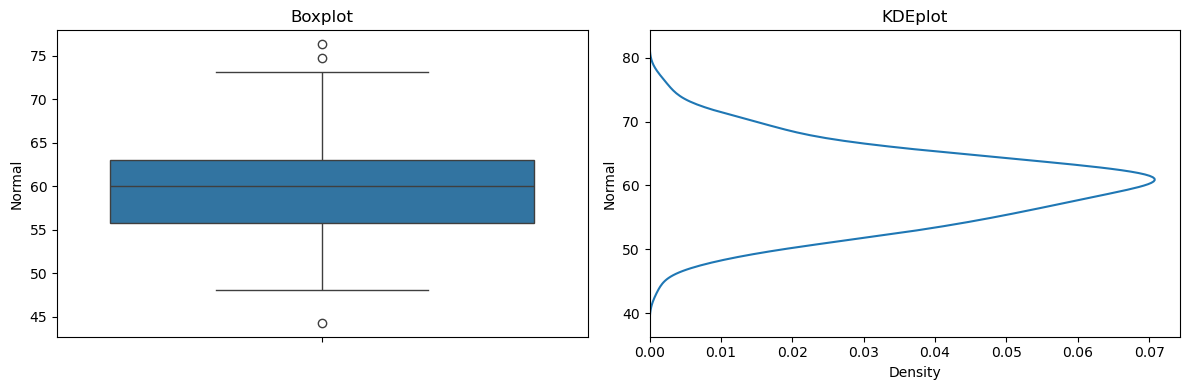

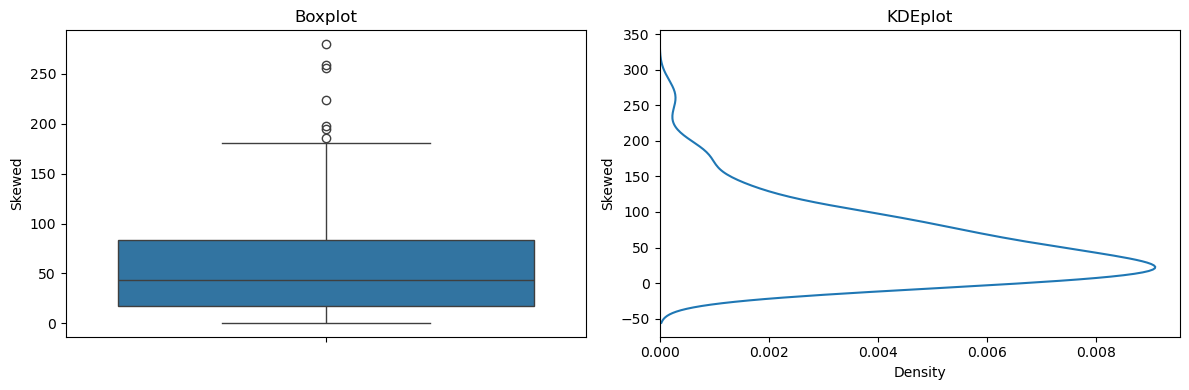

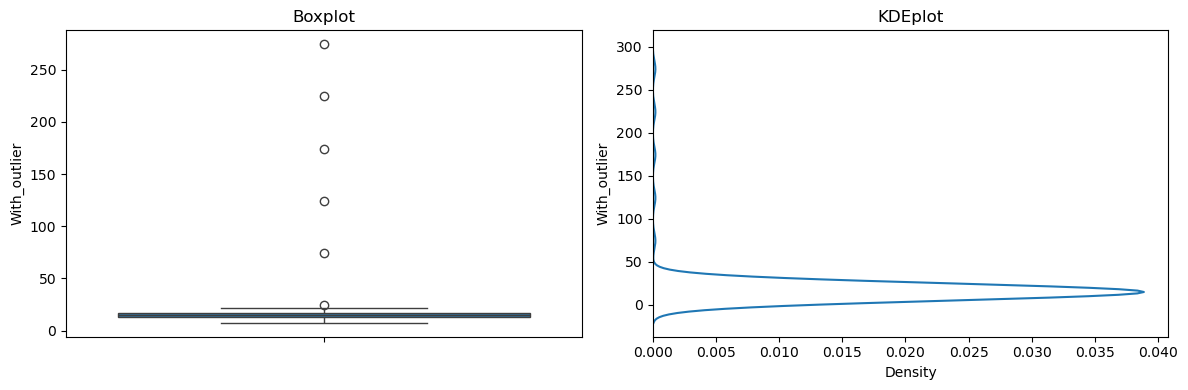

In [48]:
for col in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(y=df[col], ax=axes[0]).set_title("Boxplot")
    sns.kdeplot(y=df[col], ax=axes[1]).set_title("KDEplot")

    plt.tight_layout()
    plt.show()

# 3. Applying Scalers

In [49]:
# Initializing the scalers
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()
robust_scaler = RobustScaler()

# Fit and Transform
minmax_scal = minmax_scaler.fit_transform(df)
standard_scal = standard_scaler.fit_transform(df)
robust_scal = robust_scaler.fit_transform(df)

print(f"MinMaxScaler output: {minmax_scal[:2]} \n")
print(f"StandardScaler: {standard_scal[:2]} \n")
print(f"RobustScaler: {robust_scal[:2]} \n")

MinMaxScaler output: [[0.58361597 0.44934638 0.02658395]
 [0.46470424 0.28822778 0.03232709]] 

StandardScaler: [[ 0.57876651  1.25327389 -0.15071353]
 [-0.10498128  0.4244209  -0.09491881]] 

RobustScaler: [[ 0.41535181  1.24126977 -0.04738283]
 [-0.11117299  0.56668602  0.31205043]] 



In [50]:
df_minmax = pd.DataFrame(minmax_scal, columns = df.columns)
df_stand = pd.DataFrame(standard_scal, columns = df.columns)
df_robust = pd.DataFrame(robust_scal, columns = df.columns)

# 4. Visualizing the Scaled Distributions (Boxplot side by side)


<Axes: >

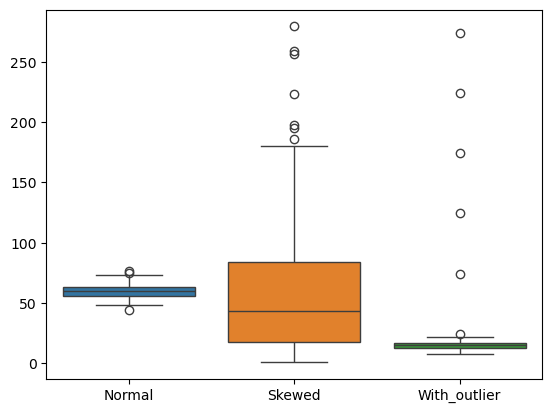

In [51]:
sns.boxplot(df)

<Axes: >

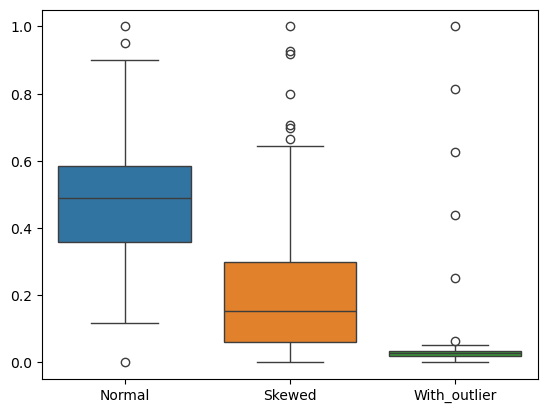

In [52]:
sns.boxplot(df_minmax)

<Axes: >

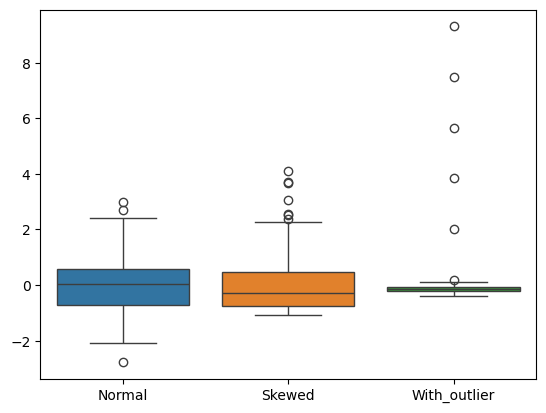

In [53]:
sns.boxplot(df_stand)

<Axes: >

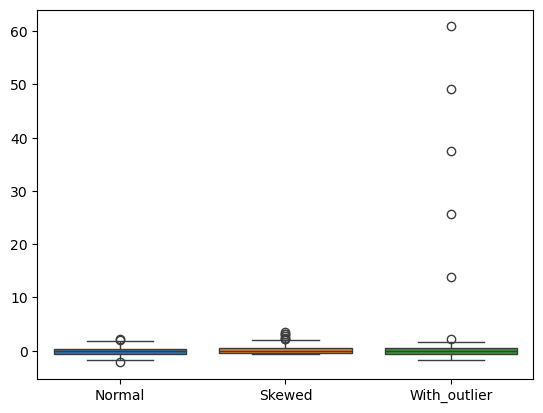

In [54]:
sns.boxplot(df_robust)

<Axes: >

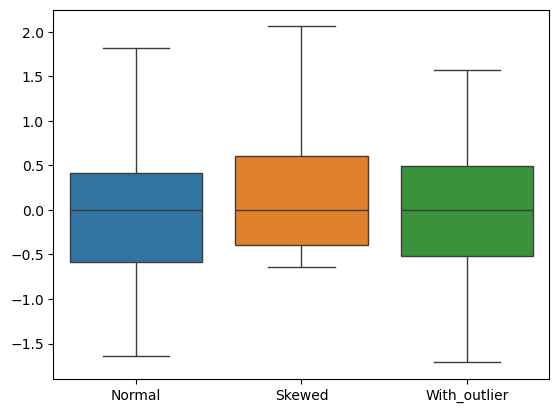

In [55]:
sns.boxplot(df_robust, showfliers = False)

# Outlier Handling Techniques (Clipping, Winsorizing & Bounding)


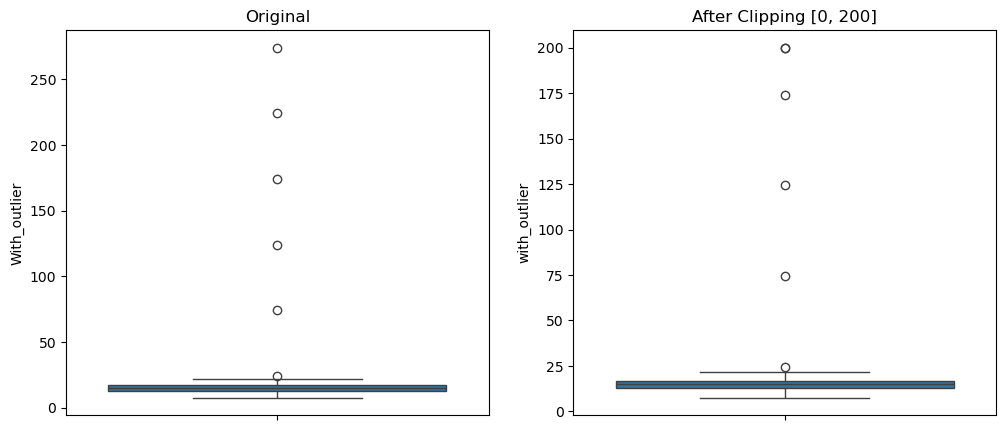

In [59]:
df_clipped = df.copy()
df_clipped['with_outlier'] = np.clip(df['With_outlier'], 0, 200)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1);
sns.boxplot(df['With_outlier']).set_title("Original")

plt.subplot(1, 2, 2);
sns.boxplot(df_clipped['with_outlier']).set_title("After Clipping [0, 200]")
plt.show()

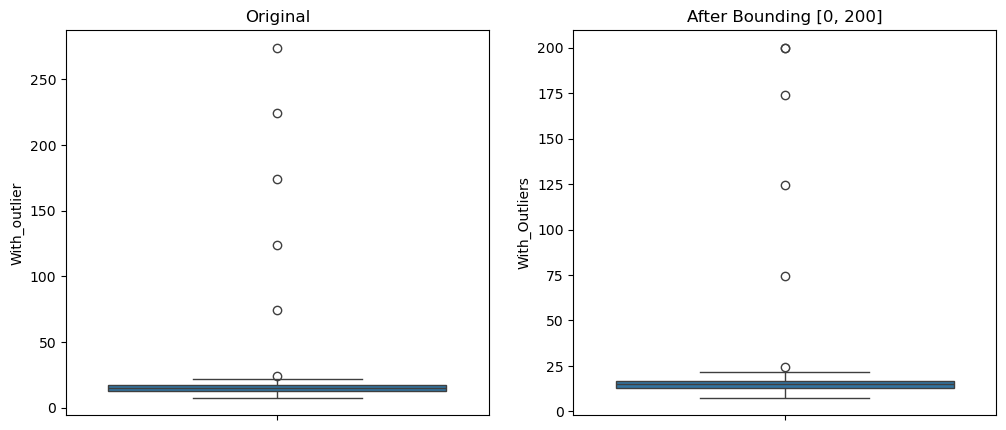

In [61]:
df_bounded = df.copy()
df_bounded['With_Outliers'] = np.clip(df['With_outlier'], 0, 200) # domain-based upper limit

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); sns.boxplot(df['With_outlier']).set_title("Original")
plt.subplot(1, 2, 2); sns.boxplot(df_bounded['With_Outliers']).set_title("After Bounding [0, 200]")
plt.show()


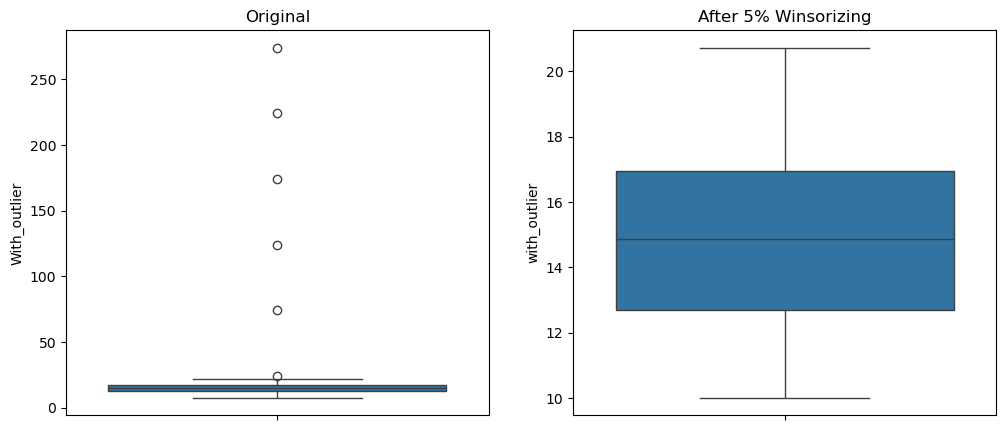

In [62]:
from scipy.stats.mstats import winsorize

df_winsor = df.copy()
df_winsor['with_outlier'] = winsorize(df['With_outlier'], limits=[0.05, 0.05])


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); sns.boxplot(df['With_outlier']).set_title("Original")
plt.subplot(1, 2, 2); sns.boxplot(df_winsor['with_outlier']).set_title("After 5% Winsorizing")
plt.show()
